# Lyft Driver Lifetime Value

Drivers are the supply side of Lyft. Every ride the platform sells depends on a driver choosing to log on, so it matters how much revenue a driver brings in over their time on the platform, and what separates high-value drivers from the rest. Those answers tell Lyft where to spend on recruiting, retention, and driver incentives.

In this project I use StrataScratch's Lyft data project to estimate each driver's **lifetime value (LTV)**. After joining and cleaning, the data covers **184,209 rides from 837 drivers** between March 28 and June 26, 2016. StrataScratch states that all rides took place in San Francisco and that all timestamps are in UTC.

**Business questions**
* What are the main factors that affect a driver's lifetime value?
* How long does a driver typically keep driving with Lyft after being onboarded?
* Do all drivers act alike, or are there segments of drivers that generate more value?
* What actionable recommendations follow for the business?

**Approach**
1. Join, clean, and reshape the raw driver, ride, and timestamp data into one row per ride.
2. Price every ride with the Lyft rate card below, then sum each driver's rides to get their LTV.
3. Build ride-level and driver-level features such as ride counts, distance, time on the platform, and time of day.
4. Use correlation analysis to find what drives LTV, and k-means clustering to group drivers into segments.
5. Turn the findings into recommendations for a cross-functional audience.

**Lyft rate card assumptions**
* Base Fare $2.00
* Cost per Mile $1.15
* Cost per Minute $0.22
* Service Fee $1.75
* Minimum Fare $5.00
* Maximum Fare $400.00

**Setup:** besides pandas, NumPy, and Matplotlib, this notebook uses seaborn, scikit-learn, and yellowbrick. Install everything with `pip install -r requirements.txt` (or `%pip install seaborn yellowbrick` from inside the notebook).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.style as style
import seaborn as sns

In [2]:
lyft_driver = pd.read_csv("Data/Raw-Data/driver_ids.csv")
lyft_rides = pd.read_csv("Data/Raw-Data/ride_ids.csv")
lyft_time = pd.read_csv("Data/Raw-Data/ride_timestamps.csv")

## Preparing the Data: Exploration, Joining, Cleaning, Reshaping

### Initial Data Exploration

In [3]:
print(lyft_driver.shape)
print(lyft_driver.info())
lyft_driver.head(10)

(937, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 937 entries, 0 to 936
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   driver_id            937 non-null    object
 1   driver_onboard_date  937 non-null    object
dtypes: object(2)
memory usage: 14.8+ KB
None


,driver_id,driver_onboard_date
0,002be0ffdc997bd5c50703158b7c2491,2016-03-29 00:00:00
1,007f0389f9c7b03ef97098422f902e62,2016-03-29 00:00:00
2,011e5c5dfc5c2c92501b8b24d47509bc,2016-04-05 00:00:00
3,0152a2f305e71d26cc964f8d4411add9,2016-04-23 00:00:00
4,01674381af7edd264113d4e6ed55ecda,2016-04-29 00:00:00
5,01788cf817698fe68eaecd7eb18b2f72,2016-05-06 00:00:00
6,0213f8b59219e32142711992ca4ec01f,2016-04-07 00:00:00
7,021e5cd15ef0bb3ec20a12af99e142b3,2016-05-07 00:00:00
8,0258e250ca195cc6258cbdc75aecd853,2016-04-26 00:00:00
9,028b5a4dcd7f4924ebfabcf2e814c014,2016-05-06 00:00:00


In [4]:
print(lyft_rides.shape)
print(lyft_rides.info())
lyft_rides.head(10)

(193502, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193502 entries, 0 to 193501
Data columns (total 5 columns):
 #   Column           Non-Null Count   Dtype 
---  ------           --------------   ----- 
 0   driver_id        193502 non-null  object
 1   ride_id          193502 non-null  object
 2   ride_distance    193502 non-null  int64 
 3   ride_duration    193502 non-null  int64 
 4   ride_prime_time  193502 non-null  int64 
dtypes: int64(3), object(2)
memory usage: 7.4+ MB
None


,driver_id,ride_id,ride_distance,ride_duration,ride_prime_time
0,002be0ffdc997bd5c50703158b7c2491,006d61cf7446e682f7bc50b0f8a5bea5,1811,327,50
1,002be0ffdc997bd5c50703158b7c2491,01b522c5c3a756fbdb12e95e87507eda,3362,809,0
2,002be0ffdc997bd5c50703158b7c2491,029227c4c2971ce69ff2274dc798ef43,3282,572,0
3,002be0ffdc997bd5c50703158b7c2491,034e861343a63ac3c18a9ceb1ce0ac69,65283,3338,25
4,002be0ffdc997bd5c50703158b7c2491,034f2e614a2f9fc7f1c2f77647d1b981,4115,823,100
5,002be0ffdc997bd5c50703158b7c2491,03d6b9d80b8a96135cb9b25178e9e203,4832,917,100
6,002be0ffdc997bd5c50703158b7c2491,04053c0ed21761e07f0b869cab5b7dd0,1575,347,0
7,002be0ffdc997bd5c50703158b7c2491,0534d432e0186625f623aaee57af98be,3056,687,25
8,002be0ffdc997bd5c50703158b7c2491,053a1621c0affcd2b9c517af5c2bc843,3940,1143,75
9,002be0ffdc997bd5c50703158b7c2491,066e92c52f59486de56cd7b8716a4ca6,3957,868,50


In [5]:
print(lyft_time.shape)
print(lyft_time.info())
lyft_time.head(10)

(970405, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 970405 entries, 0 to 970404
Data columns (total 3 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   ride_id    970405 non-null  object
 1   event      970405 non-null  object
 2   timestamp  970404 non-null  object
dtypes: object(3)
memory usage: 22.2+ MB
None


,ride_id,event,timestamp
0,00003037a262d9ee40e61b5c0718f7f0,requested_at,2016-06-13 09:39:19
1,00003037a262d9ee40e61b5c0718f7f0,accepted_at,2016-06-13 09:39:51
2,00003037a262d9ee40e61b5c0718f7f0,arrived_at,2016-06-13 09:44:31
3,00003037a262d9ee40e61b5c0718f7f0,picked_up_at,2016-06-13 09:44:33
4,00003037a262d9ee40e61b5c0718f7f0,dropped_off_at,2016-06-13 10:03:05
5,00005eae40882760d675da5effb89ae3,requested_at,2016-05-14 05:23:21
6,00005eae40882760d675da5effb89ae3,accepted_at,2016-05-14 05:23:25
7,00005eae40882760d675da5effb89ae3,arrived_at,2016-05-14 05:26:17
8,00005eae40882760d675da5effb89ae3,picked_up_at,2016-05-14 05:26:18
9,00005eae40882760d675da5effb89ae3,dropped_off_at,2016-05-14 05:34:17


### Joining the Datasets

Taking a look at the datasets, we can join the datasets together using the `ride_id` and `driver_id` columns. Also, looking at the dimensions of the datasets, it would make the most sense to left merge the lyft_rides dataset to the lyft_time dataset. Finally, merge the lyft_drivers dataset.

In [6]:
lyft_comb = pd.merge(left=lyft_time, right=lyft_rides, on="ride_id")
lyft = pd.merge(left=lyft_comb, right=lyft_driver, on="driver_id")

In [7]:
print(lyft.shape)
print(lyft.info())
lyft.head(10)


(921045, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 921045 entries, 0 to 921044
Data columns (total 8 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   ride_id              921045 non-null  object
 1   event                921045 non-null  object
 2   timestamp            921044 non-null  object
 3   driver_id            921045 non-null  object
 4   ride_distance        921045 non-null  int64 
 5   ride_duration        921045 non-null  int64 
 6   ride_prime_time      921045 non-null  int64 
 7   driver_onboard_date  921045 non-null  object
dtypes: int64(3), object(5)
memory usage: 56.2+ MB
None


,ride_id,event,timestamp,driver_id,ride_distance,ride_duration,ride_prime_time,driver_onboard_date
0,00003037a262d9ee40e61b5c0718f7f0,requested_at,2016-06-13 09:39:19,d967f5296732fa55266b5f1314e7447b,3698,1112,0,2016-04-09 00:00:00
1,00003037a262d9ee40e61b5c0718f7f0,accepted_at,2016-06-13 09:39:51,d967f5296732fa55266b5f1314e7447b,3698,1112,0,2016-04-09 00:00:00
2,00003037a262d9ee40e61b5c0718f7f0,arrived_at,2016-06-13 09:44:31,d967f5296732fa55266b5f1314e7447b,3698,1112,0,2016-04-09 00:00:00
3,00003037a262d9ee40e61b5c0718f7f0,picked_up_at,2016-06-13 09:44:33,d967f5296732fa55266b5f1314e7447b,3698,1112,0,2016-04-09 00:00:00
4,00003037a262d9ee40e61b5c0718f7f0,dropped_off_at,2016-06-13 10:03:05,d967f5296732fa55266b5f1314e7447b,3698,1112,0,2016-04-09 00:00:00
5,00005eae40882760d675da5effb89ae3,requested_at,2016-05-14 05:23:21,0656192a402808805282e60761bda088,3016,479,25,2016-04-30 00:00:00
6,00005eae40882760d675da5effb89ae3,accepted_at,2016-05-14 05:23:25,0656192a402808805282e60761bda088,3016,479,25,2016-04-30 00:00:00
7,00005eae40882760d675da5effb89ae3,arrived_at,2016-05-14 05:26:17,0656192a402808805282e60761bda088,3016,479,25,2016-04-30 00:00:00
8,00005eae40882760d675da5effb89ae3,picked_up_at,2016-05-14 05:26:18,0656192a402808805282e60761bda088,3016,479,25,2016-04-30 00:00:00
9,00005eae40882760d675da5effb89ae3,dropped_off_at,2016-05-14 05:34:17,0656192a402808805282e60761bda088,3016,479,25,2016-04-30 00:00:00


### Cleaning the Data

Since I am interested in finding the LTV, I will need to standardize some of the data to find key insights later. This includes converting the `ride_distance` values from meters to miles because the Lyft rate card calculates cost per mile. I will also convert the `ride_duration` in seconds to minutes because of the cost per minute element. I also want to make the `timestamp` and `driver_onboard_date` an actual datetime value instead of a string value.

In [8]:
lyft["ride_distance"] = lyft["ride_distance"] / 1609.34
lyft["ride_duration"] = lyft["ride_duration"] / 60

In [9]:
lyft["timestamp"] = pd.to_datetime(lyft["timestamp"], format="%Y-%m-%d %H:%M:%S")
lyft["driver_onboard_date"] = pd.to_datetime(lyft["driver_onboard_date"], format = "%Y-%m-%d %H:%M:%S")

In [10]:
print(lyft.info())

lyft

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 921045 entries, 0 to 921044
Data columns (total 8 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   ride_id              921045 non-null  object        
 1   event                921045 non-null  object        
 2   timestamp            921044 non-null  datetime64[ns]
 3   driver_id            921045 non-null  object        
 4   ride_distance        921045 non-null  float64       
 5   ride_duration        921045 non-null  float64       
 6   ride_prime_time      921045 non-null  int64         
 7   driver_onboard_date  921045 non-null  datetime64[ns]
dtypes: datetime64[ns](2), float64(2), int64(1), object(3)
memory usage: 56.2+ MB
None


,ride_id,event,timestamp,driver_id,ride_distance,ride_duration,ride_prime_time,driver_onboard_date
0,00003037a262d9ee40e61b5c0718f7f0,requested_at,2016-06-13 09:39:19,d967f5296732fa55266b5f1314e7447b,2.297836,18.533333,0,2016-04-09
1,00003037a262d9ee40e61b5c0718f7f0,accepted_at,2016-06-13 09:39:51,d967f5296732fa55266b5f1314e7447b,2.297836,18.533333,0,2016-04-09
2,00003037a262d9ee40e61b5c0718f7f0,arrived_at,2016-06-13 09:44:31,d967f5296732fa55266b5f1314e7447b,2.297836,18.533333,0,2016-04-09
3,00003037a262d9ee40e61b5c0718f7f0,picked_up_at,2016-06-13 09:44:33,d967f5296732fa55266b5f1314e7447b,2.297836,18.533333,0,2016-04-09
4,00003037a262d9ee40e61b5c0718f7f0,dropped_off_at,2016-06-13 10:03:05,d967f5296732fa55266b5f1314e7447b,2.297836,18.533333,0,2016-04-09
...,...,...,...,...,...,...,...,...
921040,ffffccd77f47a3de26dfed9a851464b4,requested_at,2016-05-18 08:44:13,f193cf4d5de76b20688d759ea7c66312,5.432040,26.916667,25,2016-05-03
921041,ffffccd77f47a3de26dfed9a851464b4,accepted_at,2016-05-18 08:44:21,f193cf4d5de76b20688d759ea7c66312,5.432040,26.916667,25,2016-05-03
921042,ffffccd77f47a3de26dfed9a851464b4,arrived_at,2016-05-18 08:44:36,f193cf4d5de76b20688d759ea7c66312,5.432040,26.916667,25,2016-05-03
921043,ffffccd77f47a3de26dfed9a851464b4,picked_up_at,2016-05-18 08:44:42,f193cf4d5de76b20688d759ea7c66312,5.432040,26.916667,25,2016-05-03


### Reshaping the Data

Now that the data is all combined, we can clean up the data within the dataframe. Taking a look at the `event` column it looks like it is single-handedly making a lot of duplicate data for the rest of the columns. The column has only 5 values: requested, accepted, arrived, picked up, and dropped off.

In [11]:
lyft["event"].unique()

array(['requested_at', 'accepted_at', 'arrived_at', 'picked_up_at',
       'dropped_off_at'], dtype=object)

In [12]:
pv_lyft = lyft.pivot_table(
    index = ["ride_id", "driver_id", "ride_distance", "ride_duration", "ride_prime_time", "driver_onboard_date"],
    columns ="event",
    values="timestamp",
    aggfunc= "first"
).reset_index()

print(pv_lyft.shape)
print(pv_lyft.info())

pv_lyft.head(10)

(184209, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 184209 entries, 0 to 184208
Data columns (total 11 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   ride_id              184209 non-null  object        
 1   driver_id            184209 non-null  object        
 2   ride_distance        184209 non-null  float64       
 3   ride_duration        184209 non-null  float64       
 4   ride_prime_time      184209 non-null  int64         
 5   driver_onboard_date  184209 non-null  datetime64[ns]
 6   accepted_at          184209 non-null  datetime64[ns]
 7   arrived_at           184208 non-null  datetime64[ns]
 8   dropped_off_at       184209 non-null  datetime64[ns]
 9   picked_up_at         184209 non-null  datetime64[ns]
 10  requested_at         184209 non-null  datetime64[ns]
dtypes: datetime64[ns](6), float64(2), int64(1), object(2)
memory usage: 15.5+ MB
None


event,ride_id,driver_id,ride_distance,ride_duration,ride_prime_time,driver_onboard_date,accepted_at,arrived_at,dropped_off_at,picked_up_at,requested_at
0,00003037a262d9ee40e61b5c0718f7f0,d967f5296732fa55266b5f1314e7447b,2.297836,18.533333,0,2016-04-09,2016-06-13 09:39:51,2016-06-13 09:44:31,2016-06-13 10:03:05,2016-06-13 09:44:33,2016-06-13 09:39:19
1,00005eae40882760d675da5effb89ae3,0656192a402808805282e60761bda088,1.874060,7.983333,25,2016-04-30,2016-05-14 05:23:25,2016-05-14 05:26:17,2016-05-14 05:34:17,2016-05-14 05:26:18,2016-05-14 05:23:21
2,000061d42cf29f73b591041d9a1b2973,c468a648519cd42da75e6aa9dadf733e,2.537686,6.766667,75,2016-04-01,2016-05-16 15:43:14,2016-05-16 15:47:29,2016-05-16 15:54:18,2016-05-16 15:47:32,2016-05-16 15:43:09
3,00006efeb0d5e3ccad7d921ddeee9900,689bdf87fb2de49f98bf4946cfaa5068,1.022780,5.533333,75,2016-04-04,2016-05-11 19:29:43,2016-05-11 19:35:11,2016-05-11 19:40:47,2016-05-11 19:35:15,2016-05-11 19:29:36
4,00012759befd5d34a0609800f6a1ee59,eece82fe623b4bb335a9b9e20eb0ca54,2.085948,13.050000,0,2016-04-28,2016-05-31 15:45:05,2016-05-31 15:46:22,2016-05-31 15:59:26,2016-05-31 15:46:23,2016-05-31 15:44:56
5,0001480a2c27492b1f8cb5fbc38ca667,38510028b6d34d1b1339fa4e70783563,1.547218,10.550000,100,2016-04-17,2016-06-05 01:58:52,2016-06-05 02:08:35,2016-06-05 02:19:07,2016-06-05 02:08:34,2016-06-05 01:58:44
6,0002033cf1878734f3ffec9ad9748b3e,7c27405cefee2fad79a81a819ca9dbe1,1.705047,7.016667,0,2016-03-29,2016-05-28 21:03:52,2016-05-28 21:05:27,2016-05-28 21:12:29,2016-05-28 21:05:28,2016-05-28 21:03:45
7,0002090d41c4050b1683e3c4f69ed1c4,68c4e63e9663a4bd8d4e435601a26a37,13.433457,36.833333,0,2016-05-04,2016-06-23 16:12:37,2016-06-23 16:19:46,2016-06-23 16:56:39,2016-06-23 16:19:49,2016-06-23 16:12:31
8,00024c06e3554012303d4caa449222f3,cf27028c2fe4a9fe00795d0d4dd23a18,0.882971,5.566667,150,2016-04-08,2016-06-19 01:55:58,2016-06-19 02:02:41,2016-06-19 02:08:53,2016-06-19 02:03:19,2016-06-19 01:55:52
9,000290b418595bfe228d2bf4d4e331df,4aa585f63fbe04dcded4019662cc47f8,1.875924,14.200000,0,2016-04-17,2016-04-30 23:30:22,2016-04-30 23:34:04,2016-04-30 23:48:19,2016-04-30 23:34:07,2016-04-30 23:30:19


Taking a look at the transformed pivot table, I will now be working with this table for future analyses and rename it to lyft_clean.

In [13]:
lyft_clean = pv_lyft

lyft_clean.head(10)

event,ride_id,driver_id,ride_distance,ride_duration,ride_prime_time,driver_onboard_date,accepted_at,arrived_at,dropped_off_at,picked_up_at,requested_at
0,00003037a262d9ee40e61b5c0718f7f0,d967f5296732fa55266b5f1314e7447b,2.297836,18.533333,0,2016-04-09,2016-06-13 09:39:51,2016-06-13 09:44:31,2016-06-13 10:03:05,2016-06-13 09:44:33,2016-06-13 09:39:19
1,00005eae40882760d675da5effb89ae3,0656192a402808805282e60761bda088,1.874060,7.983333,25,2016-04-30,2016-05-14 05:23:25,2016-05-14 05:26:17,2016-05-14 05:34:17,2016-05-14 05:26:18,2016-05-14 05:23:21
2,000061d42cf29f73b591041d9a1b2973,c468a648519cd42da75e6aa9dadf733e,2.537686,6.766667,75,2016-04-01,2016-05-16 15:43:14,2016-05-16 15:47:29,2016-05-16 15:54:18,2016-05-16 15:47:32,2016-05-16 15:43:09
3,00006efeb0d5e3ccad7d921ddeee9900,689bdf87fb2de49f98bf4946cfaa5068,1.022780,5.533333,75,2016-04-04,2016-05-11 19:29:43,2016-05-11 19:35:11,2016-05-11 19:40:47,2016-05-11 19:35:15,2016-05-11 19:29:36
4,00012759befd5d34a0609800f6a1ee59,eece82fe623b4bb335a9b9e20eb0ca54,2.085948,13.050000,0,2016-04-28,2016-05-31 15:45:05,2016-05-31 15:46:22,2016-05-31 15:59:26,2016-05-31 15:46:23,2016-05-31 15:44:56
5,0001480a2c27492b1f8cb5fbc38ca667,38510028b6d34d1b1339fa4e70783563,1.547218,10.550000,100,2016-04-17,2016-06-05 01:58:52,2016-06-05 02:08:35,2016-06-05 02:19:07,2016-06-05 02:08:34,2016-06-05 01:58:44
6,0002033cf1878734f3ffec9ad9748b3e,7c27405cefee2fad79a81a819ca9dbe1,1.705047,7.016667,0,2016-03-29,2016-05-28 21:03:52,2016-05-28 21:05:27,2016-05-28 21:12:29,2016-05-28 21:05:28,2016-05-28 21:03:45
7,0002090d41c4050b1683e3c4f69ed1c4,68c4e63e9663a4bd8d4e435601a26a37,13.433457,36.833333,0,2016-05-04,2016-06-23 16:12:37,2016-06-23 16:19:46,2016-06-23 16:56:39,2016-06-23 16:19:49,2016-06-23 16:12:31
8,00024c06e3554012303d4caa449222f3,cf27028c2fe4a9fe00795d0d4dd23a18,0.882971,5.566667,150,2016-04-08,2016-06-19 01:55:58,2016-06-19 02:02:41,2016-06-19 02:08:53,2016-06-19 02:03:19,2016-06-19 01:55:52
9,000290b418595bfe228d2bf4d4e331df,4aa585f63fbe04dcded4019662cc47f8,1.875924,14.200000,0,2016-04-17,2016-04-30 23:30:22,2016-04-30 23:34:04,2016-04-30 23:48:19,2016-04-30 23:34:07,2016-04-30 23:30:19


## Data Analysis

### Finding the Total Cost per Ride

Taking a look back at the base assumptions given by the rate card, we can use this to figure out the total cost of the ride.

Given Lyft Rates:
* Base Fare $2.00
* Cost per Mile $1.15
* Cost per Minute $0.22
* Service Fee $1.75
* Minimum Fare $5.00
* Maximum Fare $400.00

From these rate parameters, we can create a formula for calculating the ride cost by mapping out this pricing formula:

\begin{aligned}
\text{Ride Cost} = {} & \left( \text{base fare} + \text{cost per mile} \times \text{ride\_distance} + \text{cost per minute} \times \text{ride\_duration} \right) \\
& \times \left( 1 + \frac{\text{ride\_prime\_time}}{100} \right) + \text{service fee}
\end{aligned}


In [14]:
BASEFARE = 2.00
COSTPERMILE = 1.15
COSTPERMIN = 0.22
SERVICEFEE = 1.75
MINFARE = 5.00
MAXFARE = 400.00

lyft_clean['ride_total_cost'] = ( (BASEFARE + (COSTPERMILE * lyft_clean['ride_distance']) + (
    COSTPERMIN * lyft_clean['ride_duration']) ) * (1 + lyft_clean['ride_prime_time']/100) ) + SERVICEFEE

print(lyft_clean["ride_total_cost"])

0         10.469845
1          9.139378
2         12.962260
3          9.438677
4          9.019841
            ...    
184204    15.129946
184205    12.838720
184206     9.391076
184207    19.780019
184208    19.460642
Name: ride_total_cost, Length: 184209, dtype: float64


Now applying the maximum and minimum rate boundary, where the price cannot exceed $400 or be less than $5.

In [15]:
lyft_clean['ride_total_cost'] = np.where(lyft_clean['ride_total_cost'] < MINFARE, MINFARE, lyft_clean['ride_total_cost'])
lyft_clean['ride_total_cost'] = np.where(lyft_clean['ride_total_cost'] > MAXFARE, MAXFARE, lyft_clean['ride_total_cost'])

lyft_clean.head(10)

event,ride_id,driver_id,ride_distance,ride_duration,ride_prime_time,driver_onboard_date,accepted_at,arrived_at,dropped_off_at,picked_up_at,requested_at,ride_total_cost
0,00003037a262d9ee40e61b5c0718f7f0,d967f5296732fa55266b5f1314e7447b,2.297836,18.533333,0,2016-04-09,2016-06-13 09:39:51,2016-06-13 09:44:31,2016-06-13 10:03:05,2016-06-13 09:44:33,2016-06-13 09:39:19,10.469845
1,00005eae40882760d675da5effb89ae3,0656192a402808805282e60761bda088,1.874060,7.983333,25,2016-04-30,2016-05-14 05:23:25,2016-05-14 05:26:17,2016-05-14 05:34:17,2016-05-14 05:26:18,2016-05-14 05:23:21,9.139378
2,000061d42cf29f73b591041d9a1b2973,c468a648519cd42da75e6aa9dadf733e,2.537686,6.766667,75,2016-04-01,2016-05-16 15:43:14,2016-05-16 15:47:29,2016-05-16 15:54:18,2016-05-16 15:47:32,2016-05-16 15:43:09,12.962260
3,00006efeb0d5e3ccad7d921ddeee9900,689bdf87fb2de49f98bf4946cfaa5068,1.022780,5.533333,75,2016-04-04,2016-05-11 19:29:43,2016-05-11 19:35:11,2016-05-11 19:40:47,2016-05-11 19:35:15,2016-05-11 19:29:36,9.438677
4,00012759befd5d34a0609800f6a1ee59,eece82fe623b4bb335a9b9e20eb0ca54,2.085948,13.050000,0,2016-04-28,2016-05-31 15:45:05,2016-05-31 15:46:22,2016-05-31 15:59:26,2016-05-31 15:46:23,2016-05-31 15:44:56,9.019841
5,0001480a2c27492b1f8cb5fbc38ca667,38510028b6d34d1b1339fa4e70783563,1.547218,10.550000,100,2016-04-17,2016-06-05 01:58:52,2016-06-05 02:08:35,2016-06-05 02:19:07,2016-06-05 02:08:34,2016-06-05 01:58:44,13.950602
6,0002033cf1878734f3ffec9ad9748b3e,7c27405cefee2fad79a81a819ca9dbe1,1.705047,7.016667,0,2016-03-29,2016-05-28 21:03:52,2016-05-28 21:05:27,2016-05-28 21:12:29,2016-05-28 21:05:28,2016-05-28 21:03:45,7.254470
7,0002090d41c4050b1683e3c4f69ed1c4,68c4e63e9663a4bd8d4e435601a26a37,13.433457,36.833333,0,2016-05-04,2016-06-23 16:12:37,2016-06-23 16:19:46,2016-06-23 16:56:39,2016-06-23 16:19:49,2016-06-23 16:12:31,27.301809
8,00024c06e3554012303d4caa449222f3,cf27028c2fe4a9fe00795d0d4dd23a18,0.882971,5.566667,150,2016-04-08,2016-06-19 01:55:58,2016-06-19 02:02:41,2016-06-19 02:08:53,2016-06-19 02:03:19,2016-06-19 01:55:52,12.350207
9,000290b418595bfe228d2bf4d4e331df,4aa585f63fbe04dcded4019662cc47f8,1.875924,14.200000,0,2016-04-17,2016-04-30 23:30:22,2016-04-30 23:34:04,2016-04-30 23:48:19,2016-04-30 23:34:07,2016-04-30 23:30:19,9.031313


In [16]:
lyft_clean["ride_total_cost"].describe()

count    184209.000000
mean         13.539743
std           9.897662
min           5.000000
25%           8.036694
50%          10.567676
75%          15.113518
max         400.000000
Name: ride_total_cost, dtype: float64

Taking a look at the total cost per ride and its descriptive statistics, I can see that the boundaries were applied correctly. This includes the max value and the min boundaries.

### Creating Ride and Driver Features

Now that we understand driver ride value, we can now find statistics for the ride and driver to come up with the driver lifetime value and more insight for later analysis. The statistics for the ride includes:
* `ride_accept_response_time`- is the time (in minutes) driver accepted the ride after being requested
* `ride_arrival_time` - is the time (in minutes) it takes a driver to reach the pick-up location 
* `ride_wait_time` - is the amount of time the driver is waiting on the passenger once the driver reached the location
* `ride_length` - is a categorization of ride distances into 3 bins; to measure if the distance was a large, medium, or short distance 
* `ride_time` - is a categorization of when the drive was accepted - at night, morning, or evening
* `ride_date` -  is meant to show the date of the ride

In [17]:
# It is the time a driver takes to accept a ride once it is requested in minutes.
lyft_clean['ride_accept_response_time'] = (pd.to_datetime(lyft_clean['accepted_at']) - pd.to_datetime(lyft_clean['requested_at'])).astype('timedelta64[s]')/60
# It is the time a driver takes to reach the pickup location once a ride is accepted in minutes.
lyft_clean['ride_arrival_time'] = (pd.to_datetime(lyft_clean['arrived_at']) - pd.to_datetime(lyft_clean['accepted_at'])).astype('timedelta64[s]')/60
# It is the time a driver waits for the rider once the driver reaches the pickup location in minutes.
lyft_clean['ride_wait_time'] = (pd.to_datetime(lyft_clean['picked_up_at']) - pd.to_datetime(lyft_clean['arrived_at'])).astype('timedelta64[s]')/60
# divide ride distance to 3 categories (Short ride, medium ride, long ride) dependent on ride_distance column (miles)
lyft_clean["ride_length"] = np.where(lyft_clean["ride_distance"] > lyft_clean['ride_distance'].quantile(0.33), (np.where(lyft_clean["ride_distance"] < lyft_clean['ride_distance'].quantile(0.66), "med_ride", "long_ride")), "short_ride")
# divide ride time to 3 categories (Morning ride, evening ride, night ride) dependent on accepted_at column (time)
lyft_clean["ride_time"] = np.where(pd.to_datetime(lyft_clean['accepted_at']).dt.hour > 6, (np.where(pd.to_datetime(lyft_clean['accepted_at']).dt.hour <= 15, "morning_ride", (np.where(pd.to_datetime(lyft_clean['accepted_at']).dt.hour <= 21, "evening_ride", "night_ride")))), "night_ride")
# Convert accepted_at column to date
lyft_clean['ride_date'] = pd.to_datetime(lyft_clean['accepted_at']).dt.date
# Print first 3 rows in ride data
lyft_clean.head(3)

event,ride_id,driver_id,ride_distance,ride_duration,ride_prime_time,driver_onboard_date,accepted_at,arrived_at,dropped_off_at,picked_up_at,requested_at,ride_total_cost,ride_accept_response_time,ride_arrival_time,ride_wait_time,ride_length,ride_time,ride_date
0,00003037a262d9ee40e61b5c0718f7f0,d967f5296732fa55266b5f1314e7447b,2.297836,18.533333,0,2016-04-09,2016-06-13 09:39:51,2016-06-13 09:44:31,2016-06-13 10:03:05,2016-06-13 09:44:33,2016-06-13 09:39:19,10.469845,0 days,0 days 00:00:04,0 days,med_ride,morning_ride,2016-06-13
1,00005eae40882760d675da5effb89ae3,0656192a402808805282e60761bda088,1.874060,7.983333,25,2016-04-30,2016-05-14 05:23:25,2016-05-14 05:26:17,2016-05-14 05:34:17,2016-05-14 05:26:18,2016-05-14 05:23:21,9.139378,0 days,0 days 00:00:02,0 days,med_ride,night_ride,2016-05-14
2,000061d42cf29f73b591041d9a1b2973,c468a648519cd42da75e6aa9dadf733e,2.537686,6.766667,75,2016-04-01,2016-05-16 15:43:14,2016-05-16 15:47:29,2016-05-16 15:54:18,2016-05-16 15:47:32,2016-05-16 15:43:09,12.962260,0 days,0 days 00:00:04,0 days,med_ride,morning_ride,2016-05-16


Creating a histogram to see if the `ride_length` column is truly mapped out into thirds.

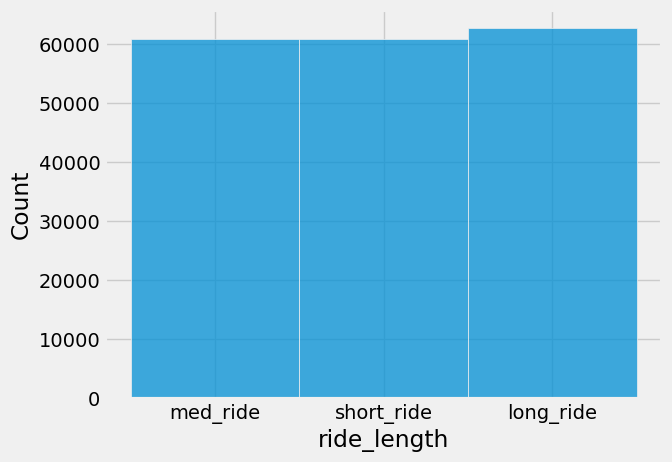

In [18]:
style.use('fivethirtyeight')
sns.histplot(lyft_clean['ride_length'])
plt.show()

Creating a new pivot table to observe and create driver statistics. These new statistics include: 
* `total_ride_count` - is the total number of rides a driver has given
* `total_distance` - is the total distance the driver has driven in miles
* `total_duration` - is the driver total time duration giving rides
* `lifetime_value` - is the sum total of the driver ride cost
* `perday_ridecount_mean` - is the average number of drives given by the driver per day
* `accept_response_time_mean` - is the average acceptance time for a driver to accept a requested drive
* `arrival_time_mean` - is the average arrival time for a driver to get to the pick-up location
* `wait_time_mean` - is the average driver waiting time at the location to pick up the rider
* `long_ride`, `med_ride`, `short_ride` - the aggregated count of the type of ride length the lyft driver gave
* `evening_ride`, `morning_ride`, `night_ride` - the aggregated count of the time of day when the ride was accepted

In [19]:
driver_day_count = lyft_clean.pivot_table(index = 'driver_id', columns = 'ride_date', aggfunc='size').fillna(0)
driver_day_count.head(3)

ride_date,2016-03-28,2016-03-29,2016-03-30,2016-03-31,2016-04-01,2016-04-02,2016-04-03,2016-04-04,2016-04-05,2016-04-06,...,2016-06-17,2016-06-18,2016-06-19,2016-06-20,2016-06-21,2016-06-22,2016-06-23,2016-06-24,2016-06-25,2016-06-26
driver_id,,,,,,,,,,,,,,,,,,,,,
002be0ffdc997bd5c50703158b7c2491,0.0,6.0,0.0,8.0,7.0,5.0,0.0,0.0,7.0,0.0,...,1.0,3.0,0.0,2.0,9.0,3.0,5.0,0.0,0.0,0.0
007f0389f9c7b03ef97098422f902e62,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0
011e5c5dfc5c2c92501b8b24d47509bc,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,3.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [20]:
driver_info = pd.DataFrame()
# Calc. driver total ride count
driver_info['total_ride_count'] = lyft_clean.pivot_table(index=['driver_id'], aggfunc='size')
# Calc. driver total ride distance
driver_info['total_distance']  = lyft_clean.groupby('driver_id')['ride_distance'].sum()
# Calc. driver total ride duration
driver_info['total_duration']  = lyft_clean.groupby('driver_id')['ride_duration'].sum()
# Calc. driver lifetime value (total revenue)
driver_info['lifetime_value'] = lyft_clean.groupby('driver_id')['ride_total_cost'].sum()
# Calc. mean driver count ride per day
driver_info['perday_ridecount_mean'] = driver_day_count.mean(axis=1)
# Calc. mean of ride accept response time for every driver
driver_info['accept_response_time_mean'] = (lyft_clean.groupby(lyft_clean['driver_id']).aggregate({'ride_accept_response_time': 'mean'})).iloc[:,0]
# Calc. mean of ride arrival time for every driver
driver_info['arrival_time_mean'] = (lyft_clean.groupby(lyft_clean['driver_id']).aggregate({'ride_arrival_time': 'mean'})).iloc[:,0]
# Calc. mean of ride wait time for every driver
driver_info['wait_time_mean'] = (lyft_clean.groupby(lyft_clean['driver_id']).aggregate({'ride_wait_time': 'mean'})).iloc[:,0]
# count total no. of short/medium/long rides
driver_info = pd.merge(driver_info, lyft_clean.pivot_table(index = 'driver_id', columns = 'ride_length', aggfunc='size') ,on='driver_id')
# count total no. of morning/evening/night rides
driver_info = pd.merge(driver_info, lyft_clean.pivot_table(index = 'driver_id', columns = 'ride_time', aggfunc='size') ,on='driver_id')
# create driver duration from most recent drive acceptance to their onboard date
driver_info["driver_duration"] = (pd.to_datetime(lyft_clean.groupby("driver_id")["accepted_at"].max()) - pd.to_datetime(lyft_clean.groupby("driver_id")["driver_onboard_date"].first())).dt.days
# updating perday mean by driver duration
driver_info["rides_per_day"] = driver_info["total_ride_count"] / driver_info["driver_duration"].replace(0, np.nan)

# fill nan value with 0
driver_info = driver_info.fillna(0).reset_index()
driver_info.head(5)

,driver_id,total_ride_count,total_distance,total_duration,lifetime_value,perday_ridecount_mean,accept_response_time_mean,arrival_time_mean,wait_time_mean,long_ride,med_ride,short_ride,evening_ride,morning_ride,night_ride,driver_duration,rides_per_day
0,002be0ffdc997bd5c50703158b7c2491,277,1081.366896,3687.300000,3560.926071,3.043956,0 days,0 days 00:00:02,0 days,79,103,95,103.0,85.0,89.0,86,3.220930
1,007f0389f9c7b03ef97098422f902e62,31,73.030559,341.616667,321.494948,0.340659,0 days,0 days 00:00:02,0 days,5,15,11,24.0,6.0,1.0,85,0.364706
2,011e5c5dfc5c2c92501b8b24d47509bc,34,167.555023,486.750000,482.428390,0.373626,0 days,0 days 00:00:03,0 days,11,11,12,24.0,8.0,2.0,68,0.500000
3,0152a2f305e71d26cc964f8d4411add9,191,914.187804,2908.683333,2610.871561,2.098901,0 days,0 days 00:00:03,0 days,99,51,41,17.0,67.0,107.0,64,2.984375
4,01674381af7edd264113d4e6ed55ecda,375,1940.947221,5957.383333,5381.097539,4.120879,0 days,0 days 00:00:03,0 days,157,111,107,0.0,350.0,25.0,56,6.696429


### Driver Total Lifetime Value

Now that we have created the driver features, we were able to create the driver total lifetime value statistic. This statistic is seen in the driver_info dataset as `lifetime_value`, where it displays the individual driver's total ride cost from all of their rides. We can see the descriptive statistics with this value below and the histogram showing the driver's lifetime value.

count      837.000000
mean      2979.859611
std       2416.913132
min         25.691325
25%        618.243836
50%       2959.141159
75%       4476.535408
max      12350.288077
Name: lifetime_value, dtype: float64


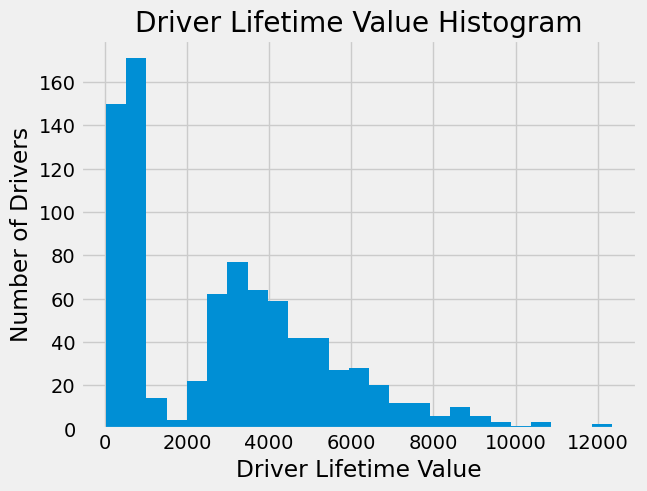

In [21]:
print(driver_info["lifetime_value"].describe())

driver_info["lifetime_value"].hist(bins=25)
plt.title('Driver Lifetime Value Histogram')
plt.xlabel('Driver Lifetime Value')
plt.ylabel('Number of Drivers')
plt.show()

Here are the rest of the `driver_info` dataset descriptive statistics and histogram. Most of the data is right skewed, which is plausible with Lyft drivers having a quick turnaround. We can see the quick driver turnaround with the `driver_duration` statistic where the driver duration is maximum 90 days since they were onboarded. This shows that most of the drivers are not going to have a large number with a small number of days since being onboarded.

In [22]:
driver_info.describe()

,total_ride_count,total_distance,total_duration,lifetime_value,perday_ridecount_mean,accept_response_time_mean,arrival_time_mean,wait_time_mean,long_ride,med_ride,short_ride,evening_ride,morning_ride,night_ride,driver_duration,rides_per_day
count,837.000000,837.000000,837.000000,837.000000,837.000000,837,837,837,837.000000,837.000000,837.000000,837.000000,837.000000,837.000000,837.000000,837.000000
mean,220.082437,949.778103,3154.046495,2979.859611,2.418488,0 days 00:00:00,0 days 00:00:03,0 days 00:00:00,74.832736,72.611708,72.637993,84.874552,85.178017,50.029869,55.075269,4.006904
std,178.180347,782.887044,2566.819072,2416.913132,1.958026,0 days 00:00:00,0 days 00:00:01,0 days 00:00:00,60.849003,60.851600,62.422290,81.688592,92.089711,64.935745,21.721934,3.155972
min,3.000000,6.148483,28.533333,25.691325,0.032967,0 days 00:00:00,0 days 00:00:01,-1 days +23:59:59,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.046875
25%,44.000000,210.654057,639.383333,618.243836,0.483516,0 days 00:00:00,0 days 00:00:02,0 days 00:00:00,18.000000,14.000000,14.000000,17.000000,15.000000,5.000000,42.000000,1.409091
50%,224.000000,901.853555,3165.100000,2959.141159,2.461538,0 days 00:00:00,0 days 00:00:03,0 days 00:00:00,71.000000,72.000000,72.000000,60.000000,44.000000,22.000000,57.000000,3.608696
75%,330.000000,1436.518076,4801.616667,4476.535408,3.626374,0 days 00:00:00,0 days 00:00:04,0 days 00:00:00,114.000000,111.000000,112.000000,140.000000,139.000000,74.000000,73.000000,5.555556
max,919.000000,4118.583394,12996.616667,12350.288077,10.098901,0 days 00:00:00,0 days 00:00:11,0 days 00:00:00,335.000000,294.000000,313.000000,404.000000,515.000000,470.000000,90.000000,35.000000


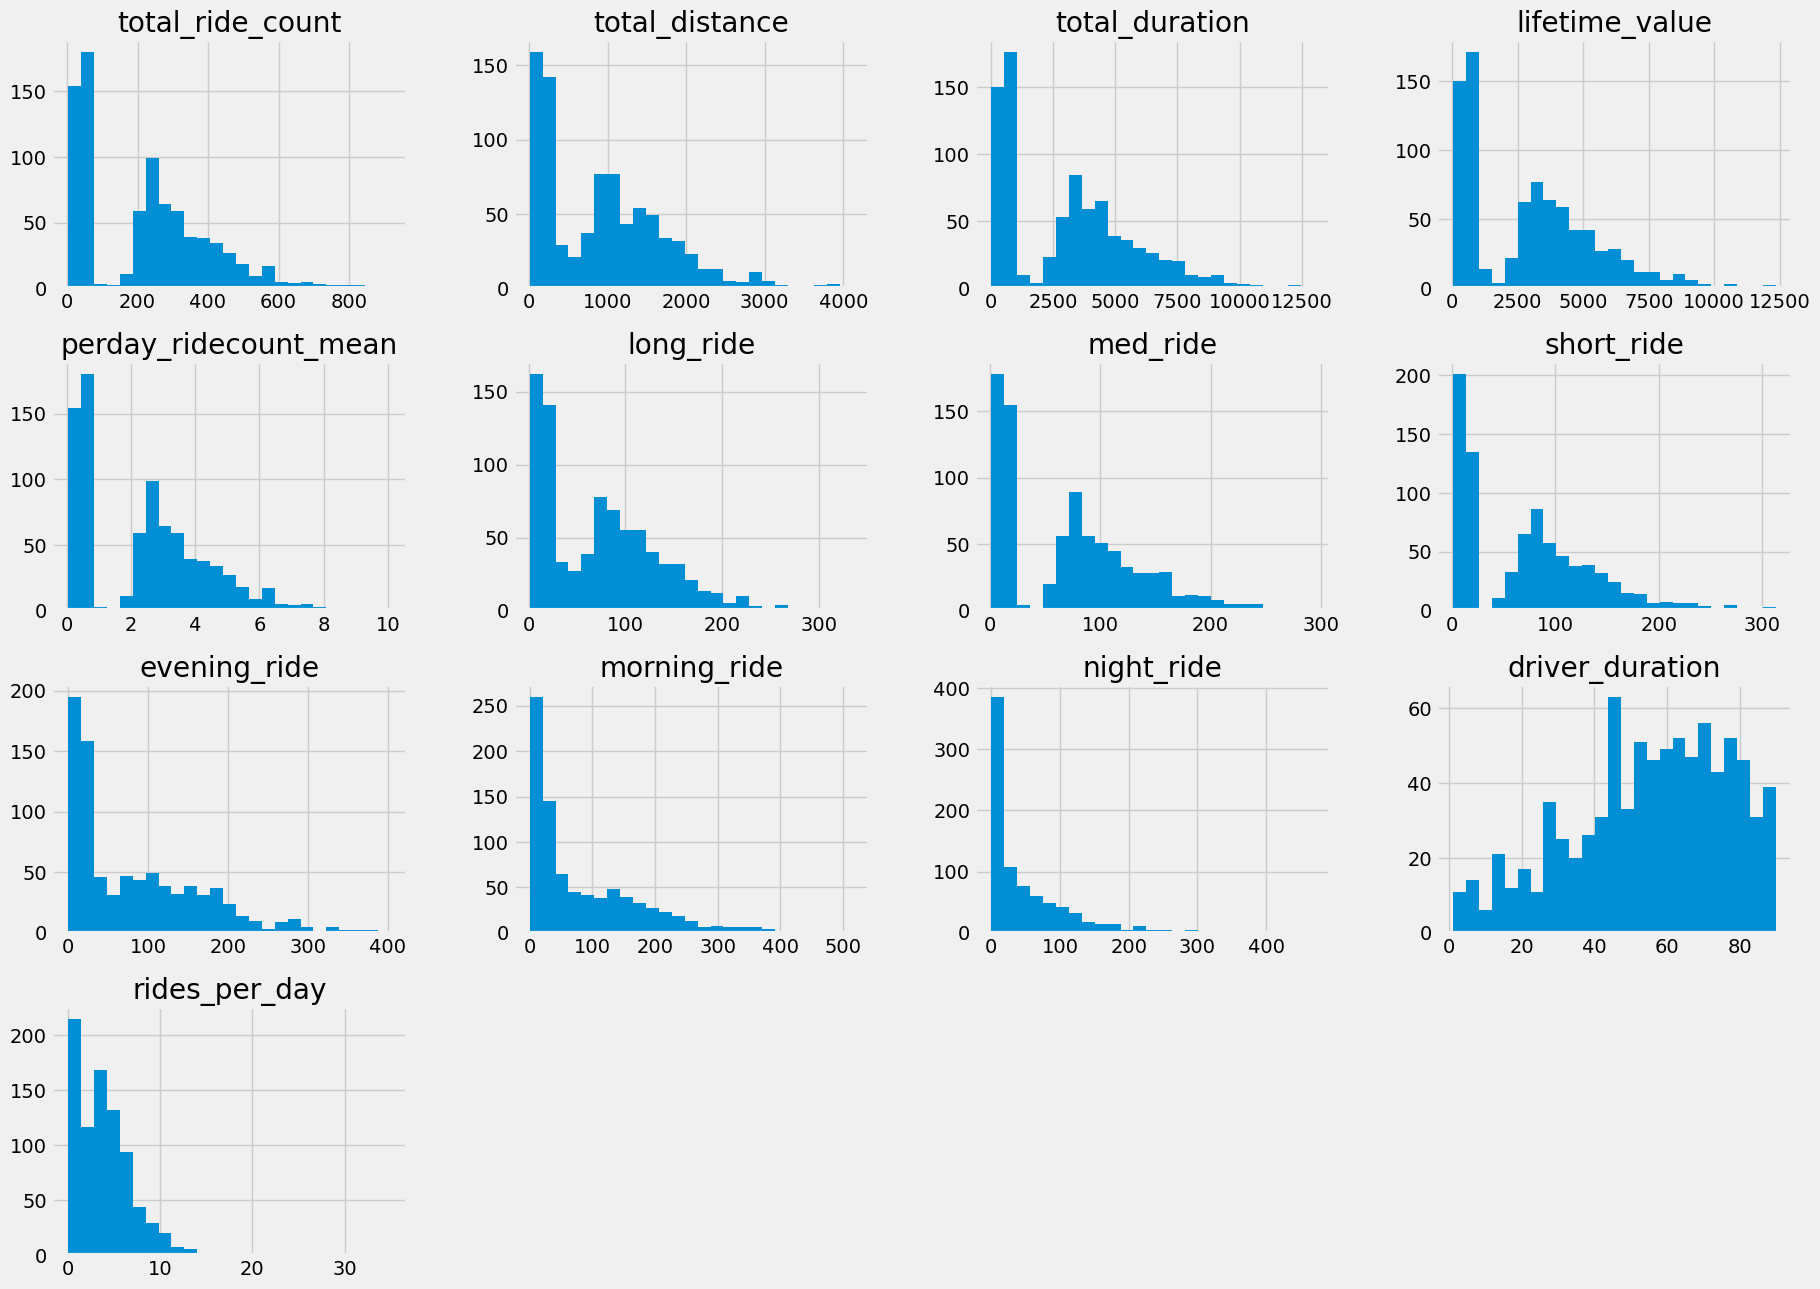

In [23]:
driver_info.hist(bins=25, figsize=(20,15))
plt.show()

## Investigating Data for Key Insights for Business Questions

We can take a deeper look at the data by looking into Lyft KPIs. Some investigative questions include:
* What are the main factors that affect a driver's lifetime value?
* What is the average projected lifetime of a driver? That is, once a driver is onboarded, how long do they typically continue driving with Lyft?
* Do all drivers act alike? Are there specific segments of drivers that generate more value for Lyft than the average driver?
* What actionable recommendations are there for the business?

### What are the main factors that affect a driver's lifetime value?

We can investigate this question by running graphs and tables displaying the correlation between driver-lifetime value and the other variables. When doing so, we can see the values with the highest correlation are `driver_duration`, `perday_ridecount_mean`, `total_ride_count`, and `total_distance`. Each of these values are above .97 r. All of these make sense because they are direct factors in making up the equation for the total ticket cost. The factors which increase the cost will increase the overall driver average for making money from the drives.

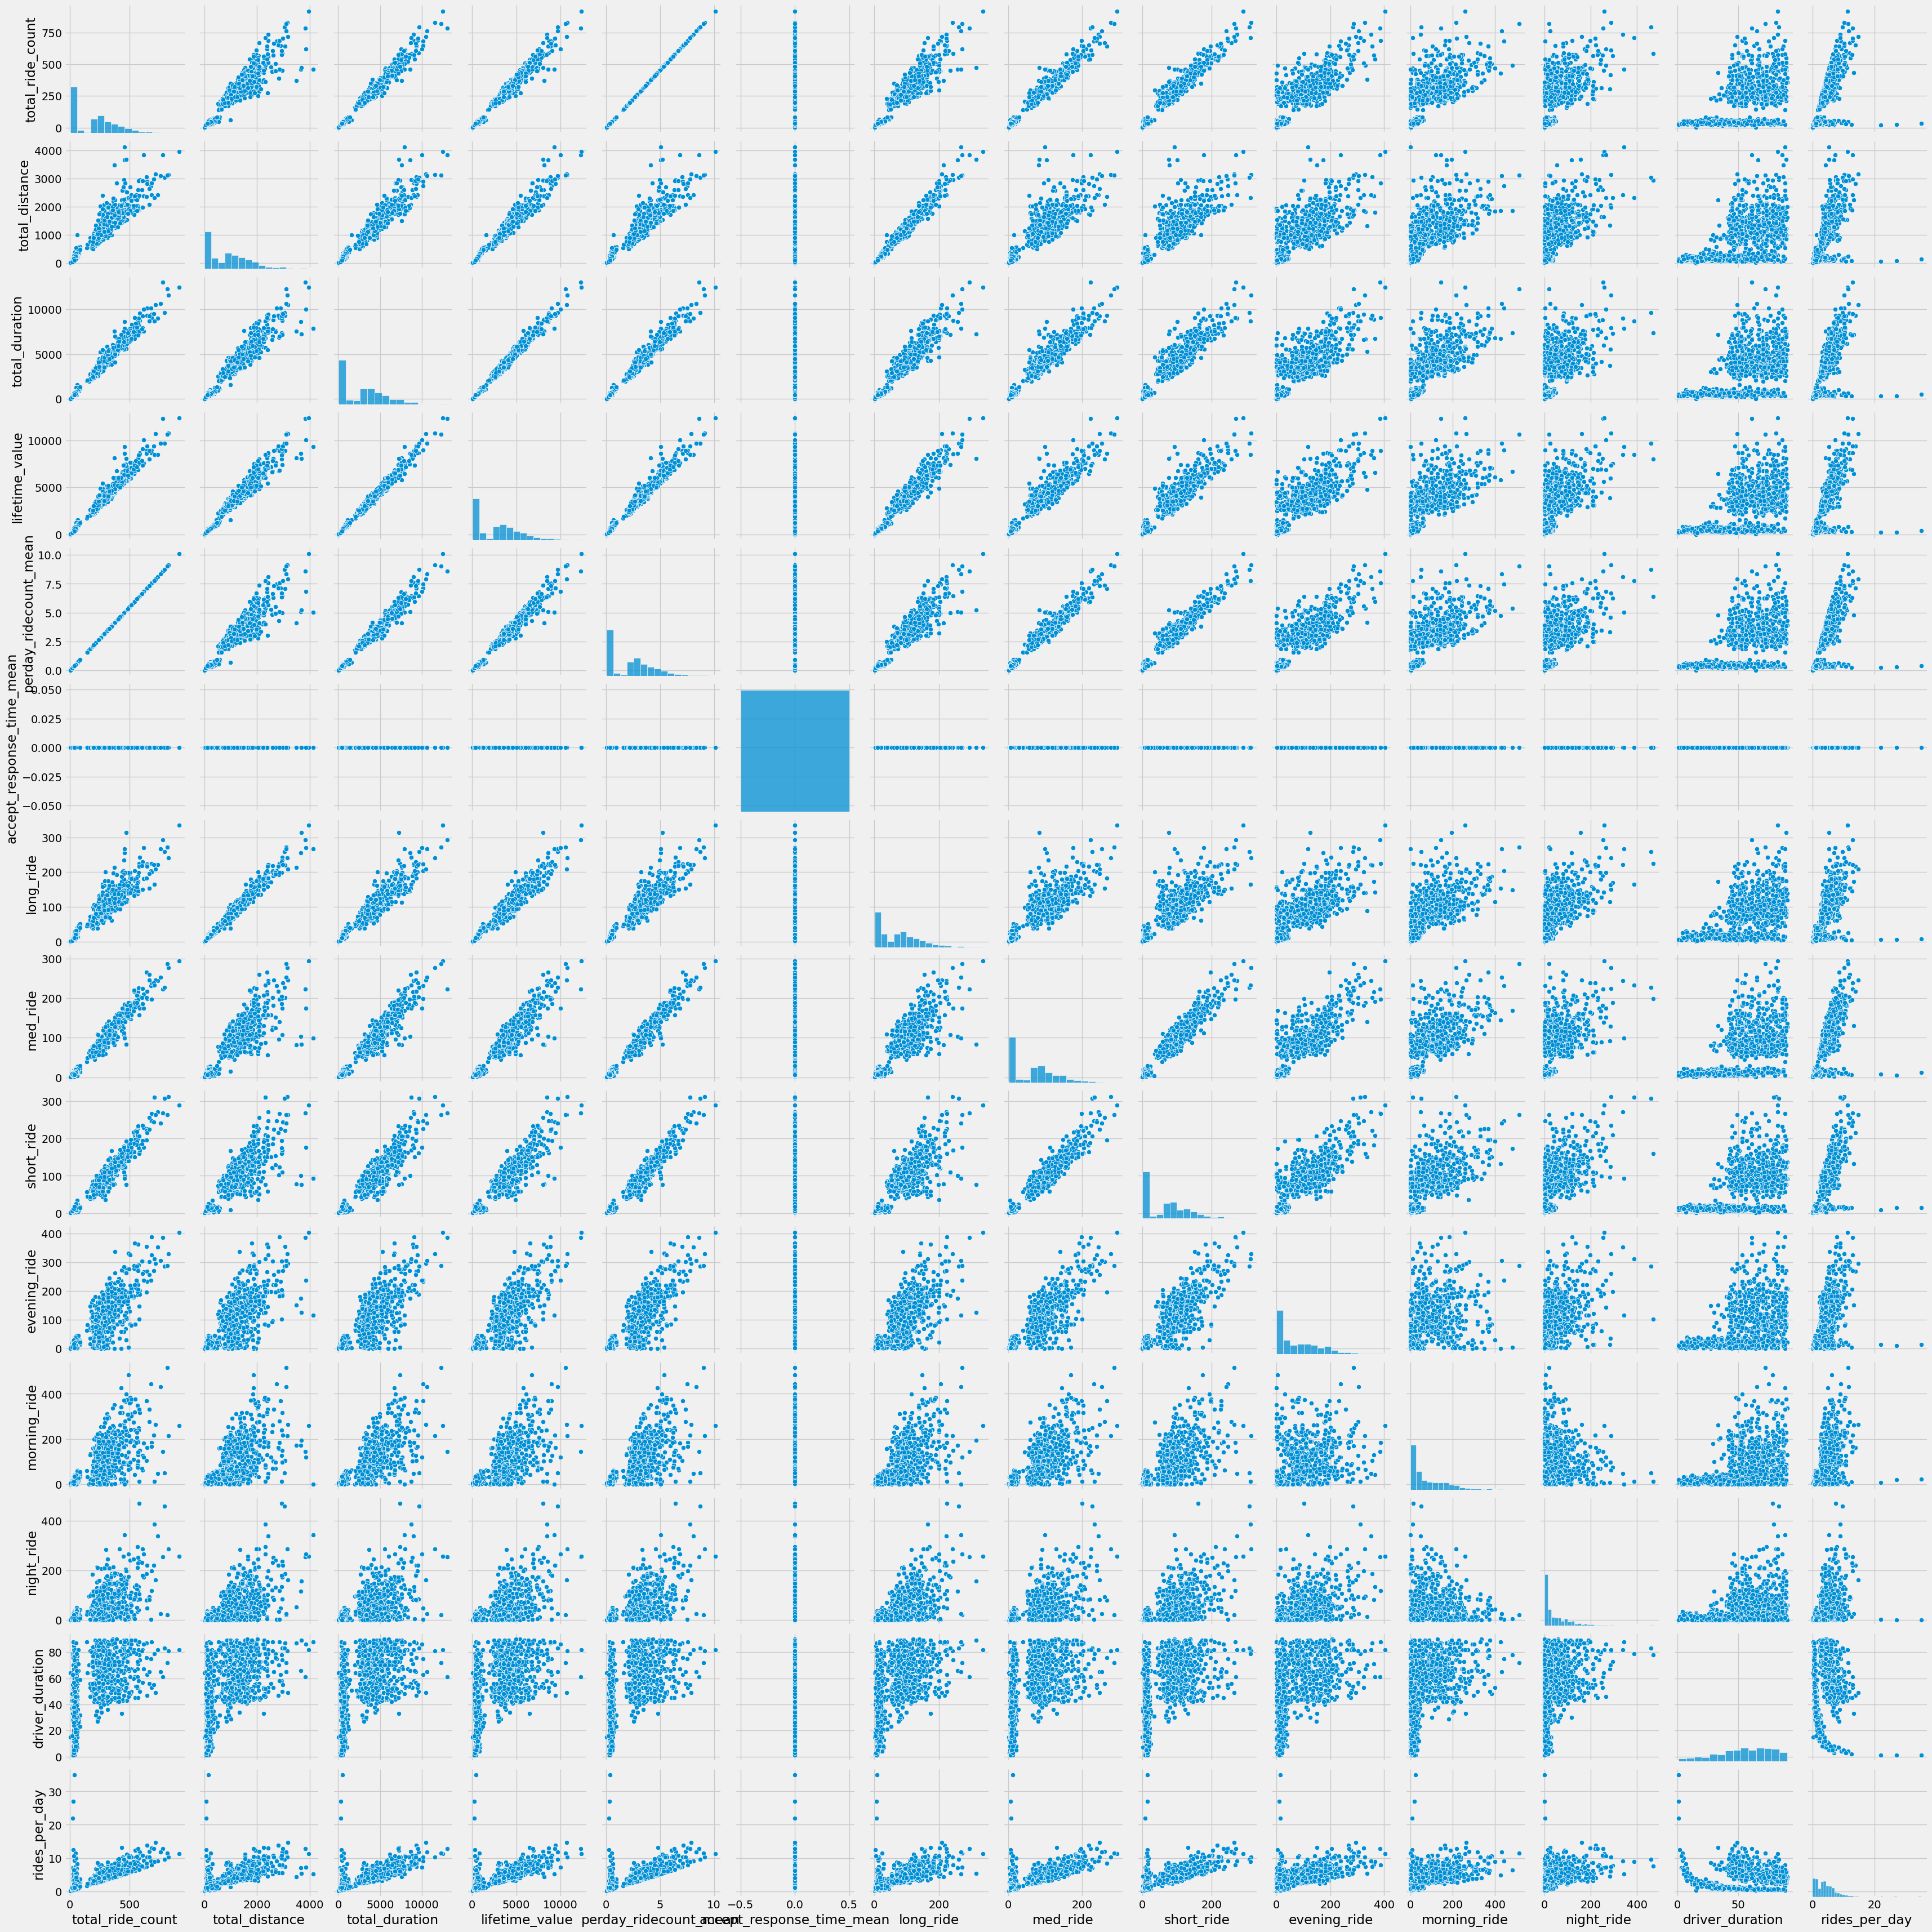

In [24]:
sns.pairplot(driver_info)
plt.show()

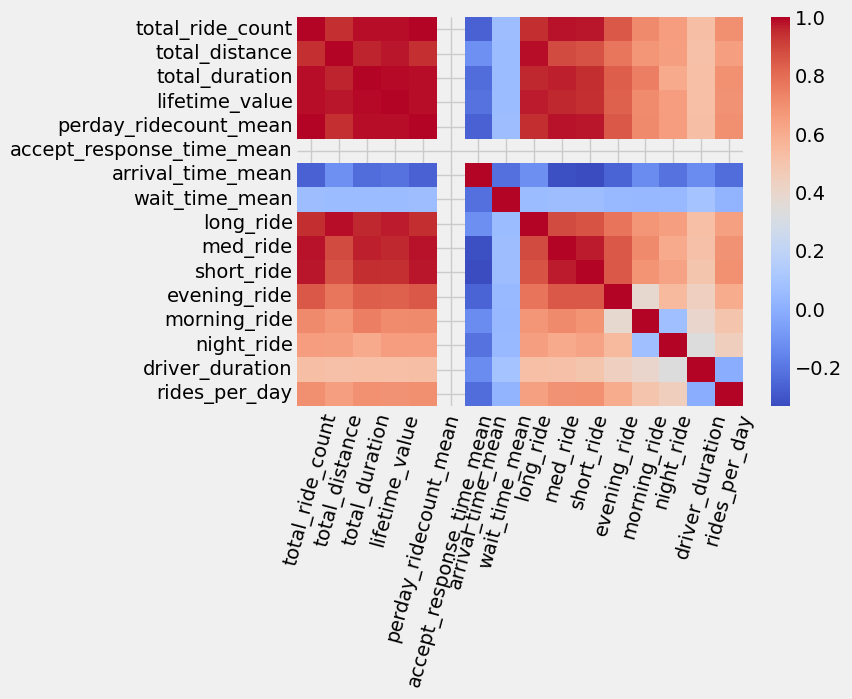

In [25]:
sns.heatmap(driver_info.select_dtypes(include='number').corr(), cmap='coolwarm')
plt.xticks(rotation=75)
plt.show()

In [26]:
pd.DataFrame(
    driver_info
    .select_dtypes(include='number')
    .corr()['lifetime_value']
).sort_values(by='lifetime_value', ascending=False).iloc[1:]

,lifetime_value
total_duration,0.994191
perday_ridecount_mean,0.987063
total_ride_count,0.987063
total_distance,0.978461
long_ride,0.971456
med_ride,0.954258
short_ride,0.940289
evening_ride,0.833408
morning_ride,0.710680
rides_per_day,0.690227


### Average Lifetime of a Driver

Taking a look at the descriptive statistics and the distribution of `driver_duration` at Lyft, we can determine the average lifetime of a driver. The mean `driver_duration` is 55 days. This makes sense if we look at the histogram of `driver_duration`, where we see a right-skew, with the right-most bin occurring at 90. With the data stopping at 90, and fewer drivers staying with the company less than 40 days, we can understand that the average would be in the 50s due to skewed nature of tail distributions and it being more than 10 days than half of 90, the max and half being 45 days.

count    837.000000
mean      55.075269
std       21.721934
min        1.000000
25%       42.000000
50%       57.000000
75%       73.000000
max       90.000000
Name: driver_duration, dtype: float64


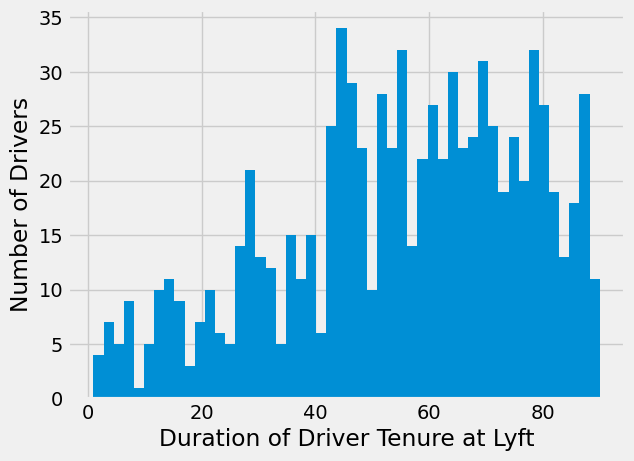

In [27]:
print(driver_info["driver_duration"].describe())

driver_info['driver_duration'].plot.hist(bins=50)
plt.xlabel('Duration of Driver Tenure at Lyft')
plt.ylabel('Number of Drivers')
plt.show()

### Do all drivers act alike?

To understand drivers not in a monolithic sense and see if there are any ways in which some drivers act that enable larger value, we perform k-means clustering and testing. We can find the optimal number of groupings by performing a k-means fit elbow curve.

In [28]:
from sklearn.cluster import KMeans
from yellowbrick.cluster import KElbowVisualizer
import warnings

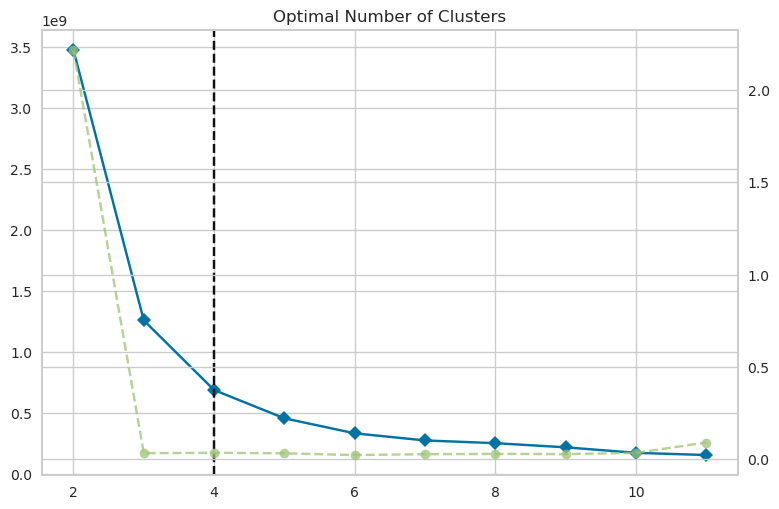

In [29]:
plt.rcParams['font.family'] = 'DejaVu Sans'
warnings.filterwarnings('ignore')

# Only take numeric columns, exclude timedeltas
clean_data = driver_info.select_dtypes(include=['number']).select_dtypes(exclude=['timedelta'])

# KMeans and visualizer
model = KMeans(random_state=42)
visualizer = KElbowVisualizer(model, k=(2, 12))
visualizer.ax.set_title("Optimal Number of Clusters", fontsize=12)
visualizer.fit(clean_data)
plt.show()

In [30]:
kmeans = KMeans(n_clusters=visualizer.elbow_value_, random_state=42)
kmeans.fit(clean_data)

driver_info['cluster'] = kmeans.labels_



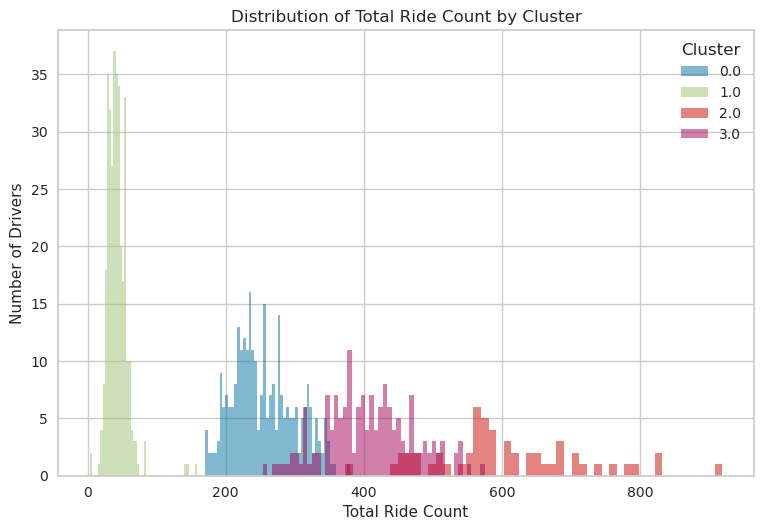

In [31]:
for col_td in driver_info.select_dtypes(include='timedelta64').columns:
        driver_info[col_td] = driver_info[col_td].dt.days

_numeric = driver_info.select_dtypes(include='number').dropna()

_kmeans = KMeans(n_clusters=int(visualizer.elbow_value_), random_state=42)
_kmeans.fit(_numeric)

driver_info['cluster_st2'] = np.nan
driver_info.loc[_numeric.index, 'cluster_st2'] = _kmeans.labels_

driver_info.groupby('cluster_st2')['total_ride_count'].plot.hist(bins=50, alpha=0.5)
plt.xlabel('Total Ride Count')
plt.ylabel('Number of Drivers')
plt.title('Distribution of Total Ride Count by Cluster')
plt.legend(title='Cluster')
plt.show()

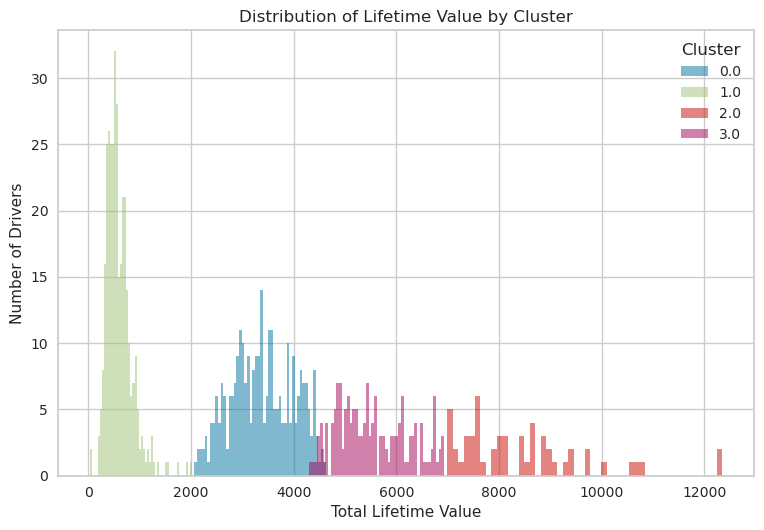

In [32]:
driver_info.groupby('cluster_st2')['lifetime_value'].plot.hist(bins=50, alpha=0.5)
plt.xlabel('Total Lifetime Value')
plt.ylabel('Number of Drivers')
plt.title('Distribution of Lifetime Value by Cluster')
plt.legend(title='Cluster')
plt.show()

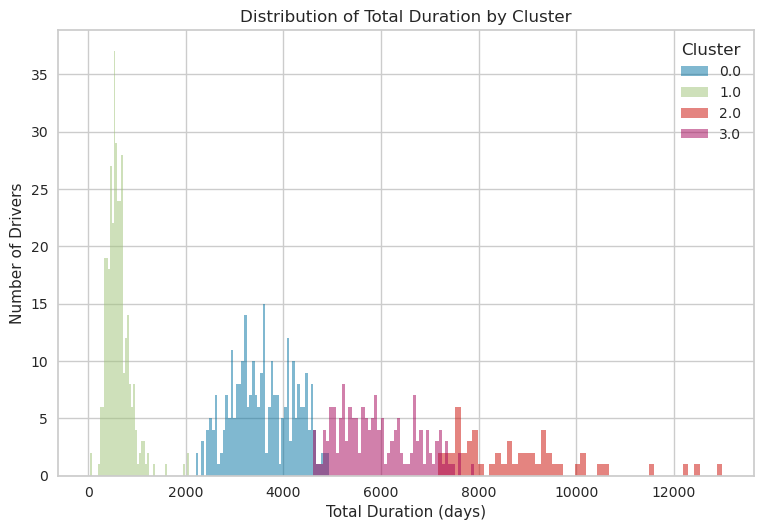

In [33]:
driver_info.groupby('cluster_st2')['total_duration'].plot.hist(bins=50, alpha=0.5)
plt.xlabel('Total Duration (days)')
plt.ylabel('Number of Drivers')
plt.title('Distribution of Total Duration by Cluster')
plt.legend(title='Cluster')
plt.show()

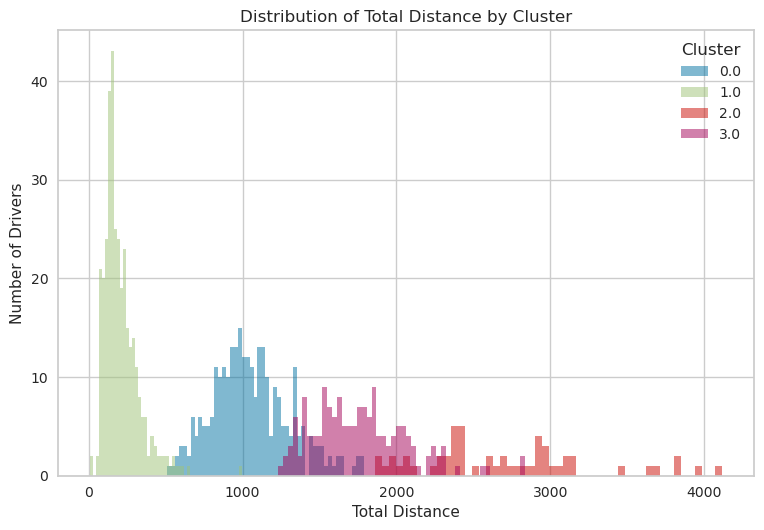

In [34]:
driver_info.groupby('cluster_st2')['total_distance'].plot.hist(bins=50, alpha=0.5)
plt.xlabel('Total Distance')
plt.ylabel('Number of Drivers')
plt.title('Distribution of Total Distance by Cluster')
plt.legend(title='Cluster')
plt.show()

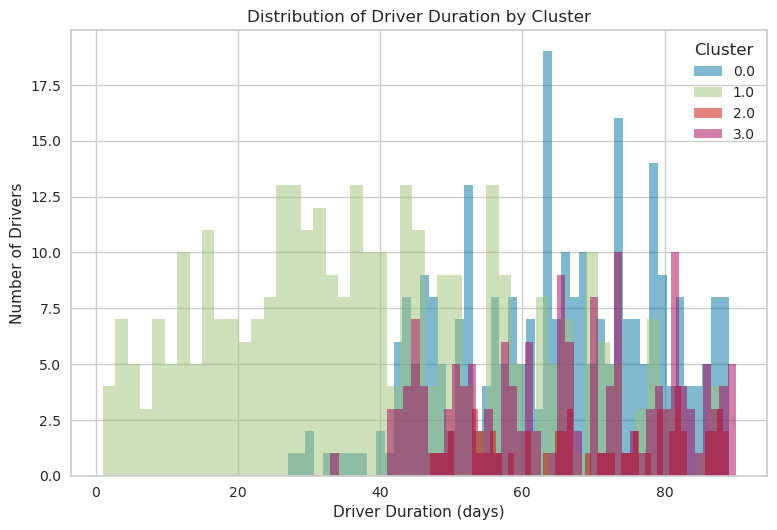

In [35]:
driver_info.groupby('cluster_st2')['driver_duration'].plot.hist(bins=50, alpha=0.5)
plt.xlabel('Driver Duration (days)')
plt.ylabel('Number of Drivers')
plt.title('Distribution of Driver Duration by Cluster')
plt.legend(title='Cluster')
plt.show()

After taking a look at the cluster and distributions, we can clearly see the key characteristics of each cluster.

* Cluster 0 - this is the cluster for middle, or fair, drivers who have the second lowest total lifetime value, but still have an average of $3,500 for CLV. They have fair numbers for total ride count, total duration and total distance. These might be Lyft drivers who do not have high demand, but also no major issues.

* Cluster 1 - this is the cluster of bad drivers, these are the drivers who have a low total lifetime value created from low total ride count, low total duration, and low total distance. This might be due to their lower driver duration in comparison to the other clusters.

* Cluster 2 - this is the cluster of excellent drivers. This cluster is the highest in every category. This cluster has the largest width in distribution total lifetime value, total ride count, total duration, and total distance, but this cluster is located always on the left-tail of the skewed histogram data. Moreover, this cluster has one of the tightest distributions in driver duration; possibly meaning they have more experience and understand how to make more value from their longer tenure.

* Cluster 3 - this is the cluster of good drivers. This cluster is the second highest in every category and has a tighter distribution on all the graphs, always on the beginning of the skewed right-tail of the histogram. These drivers have a longer tenure on average and are more experienced, perhaps why they have good value.

## What actionable recommendations are there for the business?

With the key findings from individual driver data and understanding driver lifetime value we can give good next-steps for developing the drivers and enabling the business to have consistent value.

* Retain good and excellent drivers: The good and excellent clusters bring in the most revenue and give rides most often, so keeping these drivers on the platform should be a top priority.
* Help fair drivers move up: Fair drivers are the best candidates for growth. Targeted support could turn many of them into good or excellent drivers.
* Understand why bad drivers struggle: Drivers in the bad cluster have low earnings, few rides and short ride durations. Finding the causes behind these patterns and addressing them could improve their performance.
* Tailor incentives and training to each cluster: Each cluster has different needs, so incentives and training designed for each one would work better than a single program for everyone.
* Use clusters to inform dynamic pricing: The clusters can show where and when driver supply is strong or weak. Prices can then be adjusted to match supply with demand in each area.
* Reassess drivers regularly: Drivers can move between clusters over time. Re-running the clustering regularly keeps each driver matched with the right incentives and support.

## Conclusion

Over the roughly three months of data, Lyft's 837 drivers generated about **$2.49 million** across 184,209 rides. The average driver's lifetime value was **about $2,980** (median $2,959), but the spread was wide, from $26 to more than $12,000.

**What drives LTV is volume.** Because every ride is priced by the same rate card, the drivers worth the most are the ones who drive the most. Total time spent driving (r = 0.99), rides per day (0.99), total rides (0.99), and total distance (0.98) are almost perfectly correlated with LTV. How long a driver has been on the platform matters much less (r = 0.52); what counts is how much they drive while they are there.

**Drivers stay an average of 55 days** between onboarding and their last ride in the data. The data ends on June 26, 2016, while many drivers were still active, so 55 days is a lower bound on the true driver lifetime.

**Drivers fall into four clear segments:**

| Segment | Drivers | Average LTV | Average rides | Share of revenue |
|---|---|---|---|---|
| Excellent (cluster 2) | 54 | $8,425 | 606 | 18% |
| Good (cluster 3) | 156 | $5,535 | 408 | 35% |
| Fair (cluster 0) | 287 | $3,389 | 256 | 39% |
| Low value (cluster 1) | 340 | $597 | 43 | 8% |

The excellent and good segments are a quarter of all drivers but produce **53% of revenue**. The low-value segment is 41% of drivers but produces only 8%, mostly because those drivers give few rides and stop driving sooner.

The biggest lever for Lyft is keeping high-volume drivers on the road and helping fair drivers drive more often. The recommendations above turn that into concrete actions: protect the top two segments, move fair drivers up, find out why low-value drivers leave early, and re-run this segmentation regularly as drivers change.

**Limitations:** the data covers one city over three months, prices come from an assumed rate card rather than actual fares, and the k-means clusters were built on unscaled features, so the largest-valued columns have the most influence on the segments.